<a href="https://colab.research.google.com/github/YikeCahya/PCVK_Ganjil_2026/blob/main/Week05_25.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
# ===== SEL IDENTITAS - JANGAN DIHAPUS, HARUS SEL PERTAMA =====
import sys, platform, hashlib, datetime, zoneinfo
NAMA = 'Yulike Dwi Nurcahyani'
NIM  = '244107020146'          # ganti dengan NIM Anda
N     = int(NIM[-3:])
PARAM = {
'bins' : 2 ** ((N % 4) + 3),
'clip' : round(1.0 + (N % 5) * 0.5, 1),
'tile' : (N % 4) + 2,
'L'    : 2 ** ((N % 3) + 1),
}
waktu = datetime.datetime.now(zoneinfo.ZoneInfo('Asia/Jakarta'))
print('NAMA   :', NAMA)
print('NIM    :', NIM, '| N =', N)
for k, v in PARAM.items():
    print('%-6s :' % k, v)
print('WAKTU  :', waktu.strftime('%Y-%m-%d %H:%M:%S %Z'))
print('SISTEM :', sys.version.split()[0], platform.platform())
kunci = NIM + '|' + waktu.strftime('%Y-%m-%d')
print('TOKEN  :', hashlib.sha256(kunci.encode()).hexdigest()[:16])

NAMA   : Yulike Dwi Nurcahyani
NIM    : 244107020146 | N = 146
bins   : 32
clip   : 1.5
tile   : 4
L      : 8
WAKTU  : 2026-10-03 06:29:25 WIB
SISTEM : 3.13.15 Linux-6.6.122+-x86_64-with-glibc2.39
TOKEN  : 8c286348f3599417


In [2]:
CONTOH = '/content/drive/MyDrive/Kuliah/PCVK/Images'
BASE   = '/content/drive/MyDrive/Kuliah/PCVK/Images/244107020146'

**E. PERCOBAAN PRAKTIKUM**

- E-1 PERCOBAAN HISTOGRAM

In [3]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [4]:
import cv2 as cv
from google.colab.patches import cv2_imshow
from skimage import io
import numpy as np
import matplotlib.pyplot as plt
import math
import os
import glob

Tahap 1: Verifikasi dengan Citra Contoh

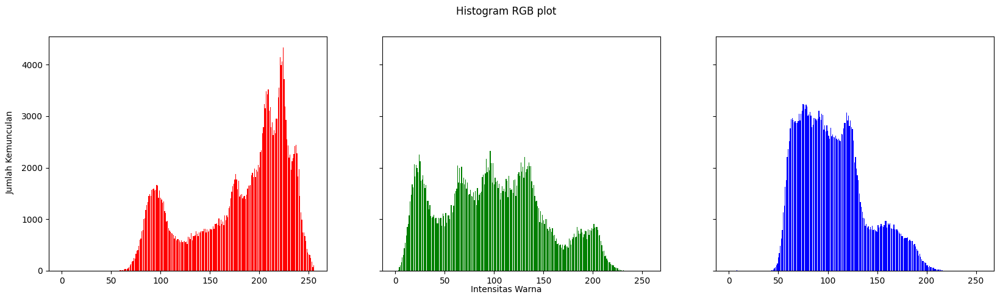

In [5]:
# 1. Membaca gambar dan konversi ruang warna
img = cv.imread(CONTOH + '/Lenna.png')
img = cv.cvtColor(img, cv.COLOR_BGR2RGB)

# 2. Mengambil dimensi gambar dan menyiapkan penampung frekuensi
height, width, depth = np.shape(img)
names = np.arange(256)

red = [0] * 256
green = [0] * 256
blue = [0] * 256

# 3. Menghitung frekuensi kemunculan setiap intensitas piksel secara manual
for y in range(0, height):
    for x in range(0, width):
        red[img[y][x][0]] += 1
        green[img[y][x][1]] += 1
        blue[img[y][x][2]] += 1

# 4. Menampilkan histogram menggunakan Matplotlib
names = np.arange(256)
fig, axs = plt.subplots(1, 3, figsize=[20, 5], sharex=True, sharey=True)
fig.suptitle('Histogram RGB plot')
fig.text(0.09, 0.5, 'Jumlah Kemunculan', va='center', rotation='vertical')
fig.text(0.5, 0.04, 'Intensitas Warna', ha='center')

axs[0].bar(names, red, color='red')
axs[1].bar(names, green, color='green')
axs[2].bar(names, blue, color='blue')

plt.show()

Tahap 2: Citra Pribadi

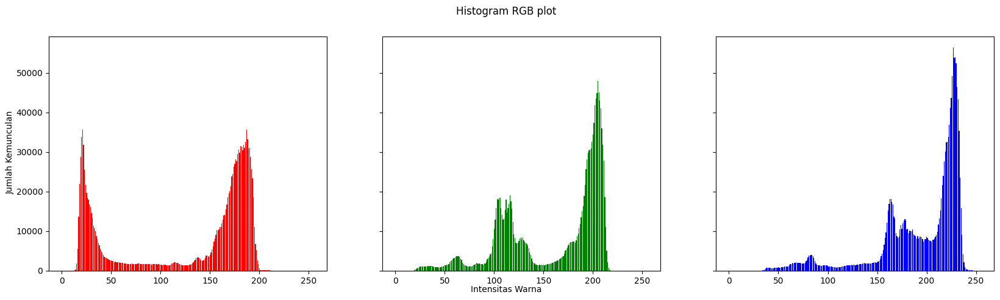

In [6]:
# 1. Membaca gambar dan konversi ruang warna
img = cv.imread(BASE + '/KTM1b.jpeg')
img = cv.cvtColor(img, cv.COLOR_BGR2RGB)

# 2. Mengambil dimensi gambar dan menyiapkan penampung frekuensi
height, width, depth = np.shape(img)
names = np.arange(256)

red = [0] * 256
green = [0] * 256
blue = [0] * 256

# 3. Menghitung frekuensi kemunculan setiap intensitas piksel secara manual
for y in range(0, height):
    for x in range(0, width):
        red[img[y][x][0]] += 1
        green[img[y][x][1]] += 1
        blue[img[y][x][2]] += 1

# 4. Menampilkan histogram menggunakan Matplotlib
names = np.arange(256)
fig, axs = plt.subplots(1, 3, figsize=[20, 5], sharex=True, sharey=True)
fig.suptitle('Histogram RGB plot')
fig.text(0.09, 0.5, 'Jumlah Kemunculan', va='center', rotation='vertical')
fig.text(0.5, 0.04, 'Intensitas Warna', ha='center')

axs[0].bar(names, red, color='red')
axs[1].bar(names, green, color='green')
axs[2].bar(names, blue, color='blue')

plt.show()

- PERTANYAAN PRAKTIKUM E1

Pertanyaan 1: Perbandingan Manual, np.histogram, dan cv.calcHist

In [7]:
def hitung_dan_bandingkan(img_path, label):
    img = cv.imread(img_path)
    # 1. Manual
    h_manual = np.zeros((256, 3), dtype=np.int64)
    for y in range(img.shape[0]):
        for x in range(img.shape[1]):
            for c in range(3):
                h_manual[img[y, x, c], c] += 1

    # 2. NumPy histogram
    h_numpy = np.zeros((256, 3), dtype=np.int64)
    for c in range(3):
        h_numpy[:, c], _ = np.histogram(img[:, :, c], bins=256, range=(0, 256))

    # 3. OpenCV calcHist
    h_cv = np.zeros((256, 3), dtype=np.int64)
    for c in range(3):
        h_cv[:, c] = cv.calcHist([img], [c], None, [256], [0, 256]).flatten().astype(np.int64)

    selisih_np_manual = np.max(np.abs(h_manual - h_numpy))
    selisih_cv_manual = np.max(np.abs(h_manual - h_cv))
    selisih_cv_np     = np.max(np.abs(h_numpy - h_cv))

    print(f"=== Pembuktian {label} ===")
    print(f"Max Diff (Manual vs NumPy) : {selisih_np_manual}")
    print(f"Max Diff (Manual vs OpenCV): {selisih_cv_manual}")
    print(f"Max Diff (NumPy vs OpenCV) : {selisih_cv_np}")
    assert selisih_np_manual == 0 and selisih_cv_manual == 0

# Verifikasi lena.jpeg
hitung_dan_bandingkan(CONTOH + '/Lenna.png', 'Lenna.png')

# Verifikasi KTM1b.jpeg
hitung_dan_bandingkan(BASE + '/KTM1b.jpeg', 'KTM1b.jpeg')

=== Pembuktian Lenna.png ===
Max Diff (Manual vs NumPy) : 0
Max Diff (Manual vs OpenCV): 0
Max Diff (NumPy vs OpenCV) : 0
=== Pembuktian KTM1b.jpeg ===
Max Diff (Manual vs NumPy) : 0
Max Diff (Manual vs OpenCV): 0
Max Diff (NumPy vs OpenCV) : 0


Penjelasan Analisis: Ketiga metode menghasilkan frekuensi piksel yang identik (selisih nol) karena ketiganya menghitung kemunculan diskret intensitas piksel $0 \le I \le 255$ tanpa aproksimasi. cv.calcHist dan np.histogram jauh lebih efisien karena diimplementasikan pada tingkat kode native C/C++.

Pertanyaan 2: Kurva Histogram Ternormalisasi $p(r_k)$ & CDF (KTM1a – KTM1d)

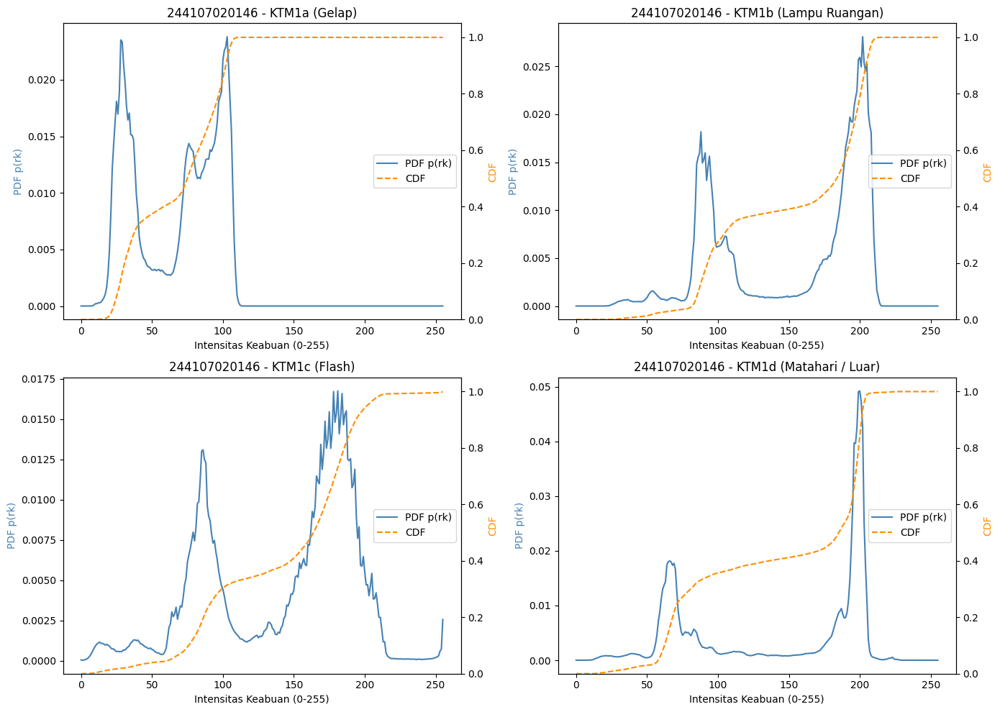

In [8]:
files = ['KTM1a.jpeg', 'KTM1b.jpeg', 'KTM1c.jpeg', 'KTM1d.jpeg']
subtitles = [
    'KTM1a (Gelap)',
    'KTM1b (Lampu Ruangan)',
    'KTM1c (Flash)',
    'KTM1d (Matahari / Luar)'
]

fig, axs = plt.subplots(2, 2, figsize=(14, 10))
axs = axs.flatten()

for idx, fname in enumerate(files):
    gray = cv.imread(BASE + '/' + fname, cv.IMREAD_GRAYSCALE)
    h, _ = np.histogram(gray, bins=256, range=(0, 256))
    p = h / gray.size
    cdf = np.cumsum(p)

    ax1 = axs[idx]
    ax2 = ax1.twinx()

    # Histogram ternormalisasi
    l1 = ax1.plot(p, color='steelblue', label='PDF p(rk)')
    ax1.set_ylabel('PDF p(rk)', color='steelblue')
    ax1.set_xlabel('Intensitas Keabuan (0-255)')

    # CDF
    l2 = ax2.plot(cdf, color='darkorange', linestyle='--', label='CDF')
    ax2.set_ylabel('CDF', color='darkorange')
    ax2.set_ylim(0, 1.05)

    ax1.set_title(f"{NIM} - {subtitles[idx]}")
    lines = l1 + l2
    labels = [l.get_label() for l in lines]
    ax1.legend(lines, labels, loc='center right')

plt.tight_layout()
plt.show()

Penjelasan Analisis Perbedaan Kurva CDF & Kondisi Pencahayaan:

- Citra Tergelap (KTM1a - Ruangan Gelap): Distribusi probabilitas $p(r_k)$ terkonsentrasi di rentang nilai rendah (mendekati 0). Akibatnya, kurva CDF langsung melonjak curam di awal (rentang intensitas gelap) dan mendatar lebih cepat menuju nilai 1.0 sebelum mencapai intensitas tengah.   
- Citra Terang (KTM1c / KTM1d - Flash atau Cahaya Matahari): Piksel didominasi oleh nilai intensitas tinggi (rentang kanan). Hal ini membuat kurva CDF tetap landai mendekati 0 pada nilai intensitas rendah, lalu mulai naik secara tajam mendekati nilai 255.   
- Korelasi: Kurva CDF merepresentasikan akumulasi energi cahaya; kecuraman di awal mengindikasikan underexposure (kurang cahaya), sedangkan kecuraman di akhir mengindikasikan overexposure atau paparan cahaya langsung yang kuat.

Pertanyaan 3: Perbandingan Histogram PARAM['bins'] vs 256 Bin

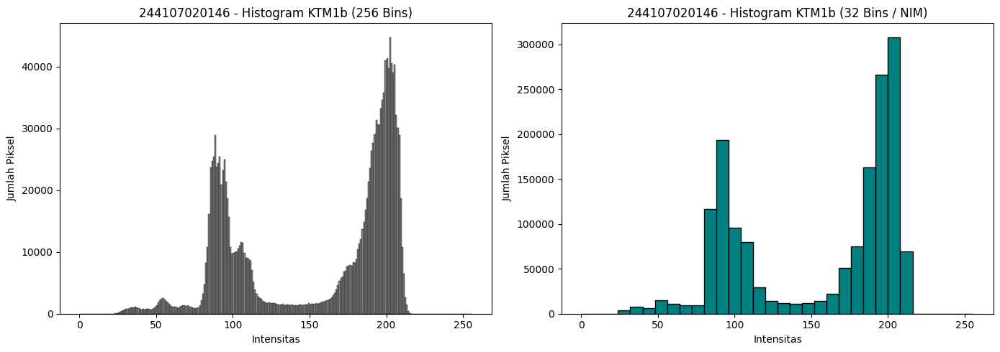

In [9]:
gray_ktm = cv.imread(BASE + '/KTM1b.jpeg', cv.IMREAD_GRAYSCALE)
n_bins_param = PARAM['bins']

fig, axs = plt.subplots(1, 2, figsize=(14, 5))

# 256 bins
axs[0].hist(gray_ktm.ravel(), bins=256, range=[0, 256], color='gray', edgecolor='black', linewidth=0.3)
axs[0].set_title(f"{NIM} - Histogram KTM1b (256 Bins)")
axs[0].set_xlabel('Intensitas')
axs[0].set_ylabel('Jumlah Piksel')

# PARAM['bins']
axs[1].hist(gray_ktm.ravel(), bins=n_bins_param, range=[0, 256], color='teal', edgecolor='black')
axs[1].set_title(f"{NIM} - Histogram KTM1b ({n_bins_param} Bins / NIM)")
axs[1].set_xlabel('Intensitas')
axs[1].set_ylabel('Jumlah Piksel')

plt.tight_layout()
plt.show()

- Informasi yang Hilang saat Bin Dikurangi:
  - Pengurangan jumlah bin menyebabkan terjadinya pengelompokan (binning/kuantisasi rentang).   
  - Detail frekuensi lokal hilang: Variasi halus, puncak-puncak kecil (sub-peaks), dan celah intensitas (gaps) antarnilai abu-abu yang berdekatan melebur menjadi satu interval akumulasi.
  - Bentuk distribusi menjadi representasi kasar (coarse approximation), yang mengurangi akurasi deteksi kontras mikro namun membantu melihat kecenderungan umum distribusi citra tanpa terganggu oleh derau lokal (noise).

- E-2 PERCOBAAN HISTOGRAM EQUALIZATION

  Langkah 1: Implementasi Manual

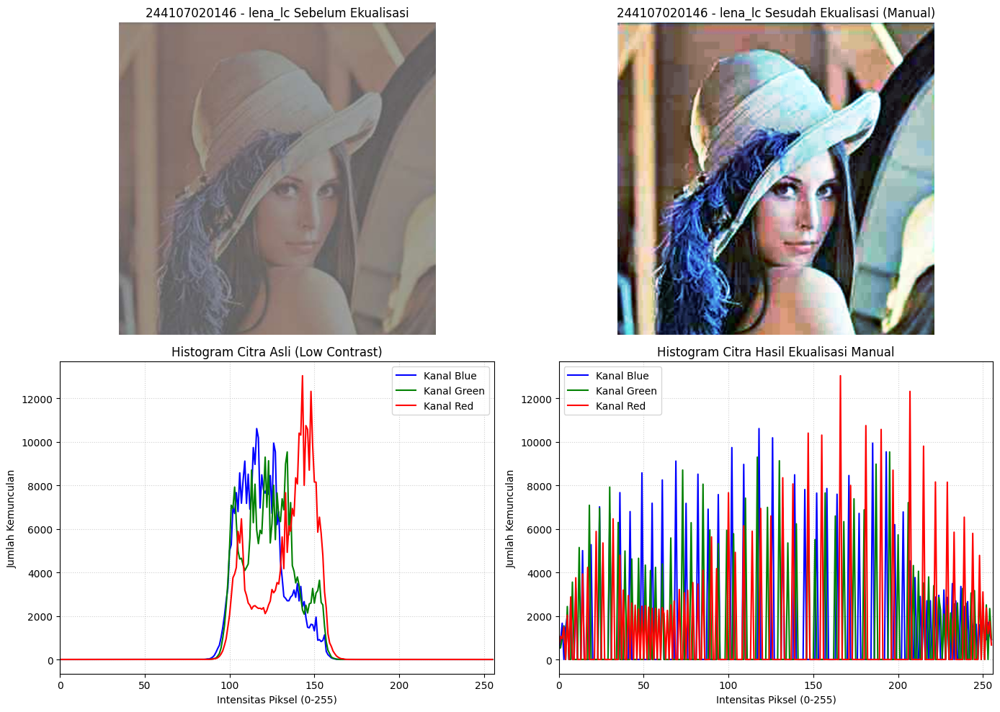

In [16]:
def he_manual_channel(channel):
    # Hitung frekuensi piksel
    hist, _ = np.histogram(channel.flatten(), bins=256, range=[0, 256])
    # Penjumlahan kumulatif (CDF)
    cdf = hist.cumsum()
    # Pemetaan ke rentang 0-255 (LUT)
    lut = np.round((cdf / channel.size) * 255.0).astype(np.uint8)
    return lut[channel]

def he_manual_rgb(img_bgr):
    # Ekualisasi manual per kanal B, G, R
    b, g, r = cv.split(img_bgr)
    return cv.merge([he_manual_channel(b), he_manual_channel(g), he_manual_channel(r)])

# 1. Baca citra low-contrast berwarna
path_lena_lc = CONTOH + '/lena_lc.png'
img_asli_bgr = cv.imread(path_lena_lc)

# 2. Proses ekualisasi manual
img_eq_bgr = he_manual_rgb(img_asli_bgr)

# 3. Konversi ke RGB untuk Matplotlib
img_asli_rgb = cv.cvtColor(img_asli_bgr, cv.COLOR_BGR2RGB)
img_eq_rgb   = cv.cvtColor(img_eq_bgr, cv.COLOR_BGR2RGB)

# 4. Tampilkan Citra + Histogram (Layout 2x2)
fig, axs = plt.subplots(2, 2, figsize=(14, 10))

# --- Citra Sebelum Ekualisasi ---
axs[0, 0].imshow(img_asli_rgb)
axs[0, 0].set_title(f"{NIM} - lena_lc Sebelum Ekualisasi")
axs[0, 0].axis('off')

# --- Citra Sesudah Ekualisasi ---
axs[0, 1].imshow(img_eq_rgb)
axs[0, 1].set_title(f"{NIM} - lena_lc Sesudah Ekualisasi (Manual)")
axs[0, 1].axis('off')

# --- Histogram Sebelum Ekualisasi ---
for i, col in enumerate(['blue', 'green', 'red']):
    hist_asli, _ = np.histogram(img_asli_bgr[:, :, i], bins=256, range=[0, 256])
    axs[1, 0].plot(hist_asli, color=col, label=f'Kanal {col.capitalize()}')
axs[1, 0].set_title("Histogram Citra Asli (Low Contrast)")
axs[1, 0].set_xlabel("Intensitas Piksel (0-255)")
axs[1, 0].set_ylabel("Jumlah Kemunculan")
axs[1, 0].set_xlim([0, 256])
axs[1, 0].grid(True, linestyle=':', alpha=0.6)
axs[1, 0].legend()

# --- Histogram Sesudah Ekualisasi ---
for i, col in enumerate(['blue', 'green', 'red']):
    hist_eq, _ = np.histogram(img_eq_bgr[:, :, i], bins=256, range=[0, 256])
    axs[1, 1].plot(hist_eq, color=col, label=f'Kanal {col.capitalize()}')
axs[1, 1].set_title("Histogram Citra Hasil Ekualisasi Manual")
axs[1, 1].set_xlabel("Intensitas Piksel (0-255)")
axs[1, 1].set_ylabel("Jumlah Kemunculan")
axs[1, 1].set_xlim([0, 256])
axs[1, 1].grid(True, linestyle=':', alpha=0.6)
axs[1, 1].legend()

plt.tight_layout()
plt.show()

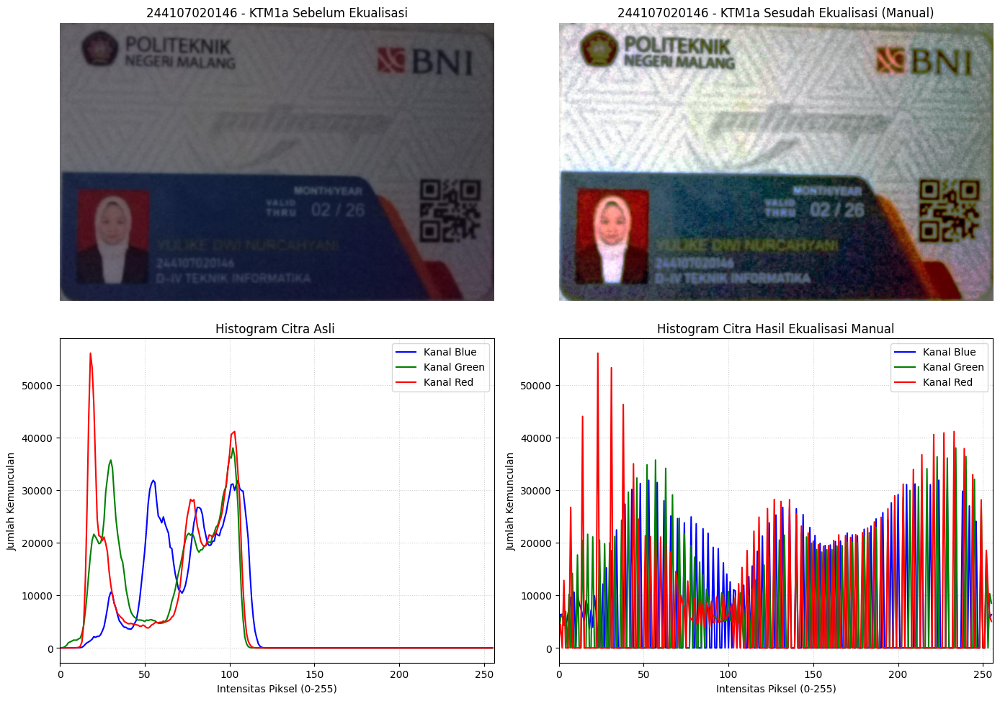

In [17]:
def he_manual_channel(channel):
    # Hitung frekuensi piksel
    hist, _ = np.histogram(channel.flatten(), bins=256, range=[0, 256])
    # Penjumlahan kumulatif (CDF)
    cdf = hist.cumsum()
    # Pemetaan ke rentang 0-255 (LUT)
    lut = np.round((cdf / channel.size) * 255.0).astype(np.uint8)
    return lut[channel]

def he_manual_rgb(img_bgr):
    # Ekualisasi manual per kanal B, G, R
    b, g, r = cv.split(img_bgr)
    return cv.merge([he_manual_channel(b), he_manual_channel(g), he_manual_channel(r)])

# 1. Baca citra low-contrast berwarna
path_KTM1a = BASE + '/KTM1a.jpeg'
img_asli_bgr = cv.imread(path_KTM1a)

# 2. Proses ekualisasi manual
img_eq_bgr = he_manual_rgb(img_asli_bgr)

# 3. Konversi ke RGB untuk Matplotlib
img_asli_rgb = cv.cvtColor(img_asli_bgr, cv.COLOR_BGR2RGB)
img_eq_rgb   = cv.cvtColor(img_eq_bgr, cv.COLOR_BGR2RGB)

# 4. Tampilkan Citra + Histogram (Layout 2x2)
fig, axs = plt.subplots(2, 2, figsize=(14, 10))

# --- Citra Sebelum Ekualisasi ---
axs[0, 0].imshow(img_asli_rgb)
axs[0, 0].set_title(f"{NIM} - KTM1a Sebelum Ekualisasi")
axs[0, 0].axis('off')

# --- Citra Sesudah Ekualisasi ---
axs[0, 1].imshow(img_eq_rgb)
axs[0, 1].set_title(f"{NIM} - KTM1a Sesudah Ekualisasi (Manual)")
axs[0, 1].axis('off')

# --- Histogram Sebelum Ekualisasi ---
for i, col in enumerate(['blue', 'green', 'red']):
    hist_asli, _ = np.histogram(img_asli_bgr[:, :, i], bins=256, range=[0, 256])
    axs[1, 0].plot(hist_asli, color=col, label=f'Kanal {col.capitalize()}')
axs[1, 0].set_title("Histogram Citra Asli ")
axs[1, 0].set_xlabel("Intensitas Piksel (0-255)")
axs[1, 0].set_ylabel("Jumlah Kemunculan")
axs[1, 0].set_xlim([0, 256])
axs[1, 0].grid(True, linestyle=':', alpha=0.6)
axs[1, 0].legend()

# --- Histogram Sesudah Ekualisasi ---
for i, col in enumerate(['blue', 'green', 'red']):
    hist_eq, _ = np.histogram(img_eq_bgr[:, :, i], bins=256, range=[0, 256])
    axs[1, 1].plot(hist_eq, color=col, label=f'Kanal {col.capitalize()}')
axs[1, 1].set_title("Histogram Citra Hasil Ekualisasi Manual")
axs[1, 1].set_xlabel("Intensitas Piksel (0-255)")
axs[1, 1].set_ylabel("Jumlah Kemunculan")
axs[1, 1].set_xlim([0, 256])
axs[1, 1].grid(True, linestyle=':', alpha=0.6)
axs[1, 1].legend()

plt.tight_layout()
plt.show()

Langkah 2: Perbandingan Ekualisasi Manual dengan cv.equalizeHist

=== Hasil Uji E-2 Langkah 2 ===
Selisih Maksimum (Manual vs cv.equalizeHist): 0


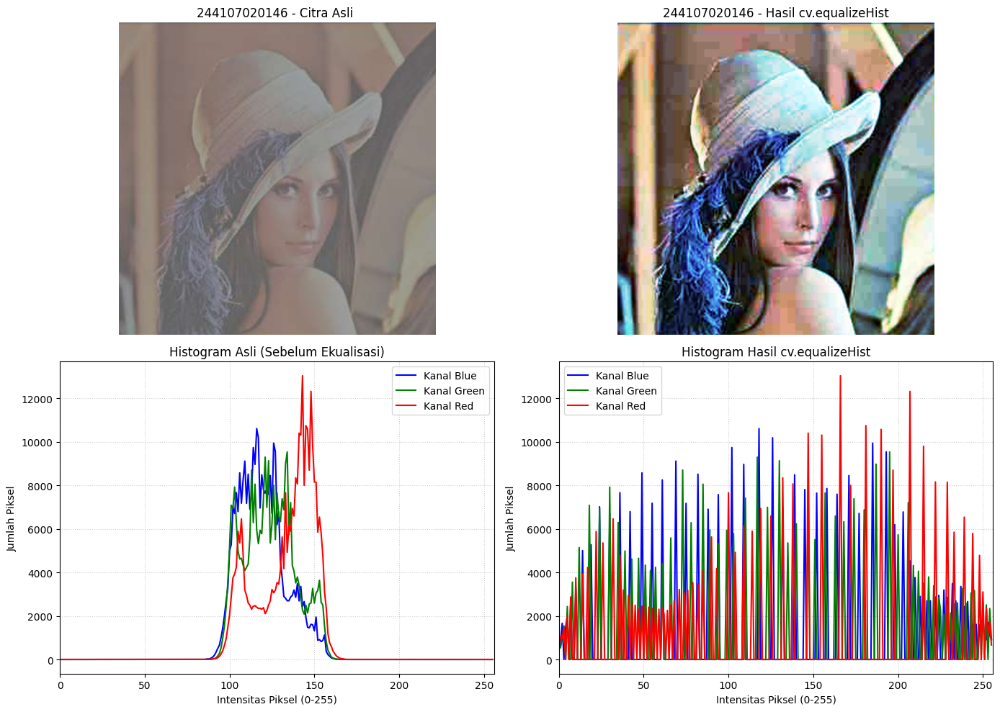

In [19]:
# Baca citra berwarna
image = cv.imread(CONTOH + '/lena_lc.png')

# Pisahkan dan ekualisasi tiap kanal menggunakan OpenCV
b, g, r = cv.split(image)
b_equalized = cv.equalizeHist(b)
g_equalized = cv.equalizeHist(g)
r_equalized = cv.equalizeHist(r)

# Gabungkan kembali kanal-kanal yang telah diekualisasi
img_cv_eq = cv.merge([b_equalized, g_equalized, r_equalized])

# Memproses secara manual khusus untuk gambar yang aktif agar ukurannya sama
img_eq_bgr_lokal = he_manual_rgb(image)

# Hitung selisih maksimum dengan dimensi yang sudah sesuai
selisih_maks = np.max(np.abs(img_eq_bgr_lokal.astype(np.int16) - img_cv_eq.astype(np.int16)))

print("=== Hasil Uji E-2 Langkah 2 ===")
print(f"Selisih Maksimum (Manual vs cv.equalizeHist): {selisih_maks}")

fig, axs = plt.subplots(2, 2, figsize=(14, 10))

# Citra Asli vs Citra Hasil equalizeHist
axs[0, 0].imshow(cv.cvtColor(image, cv.COLOR_BGR2RGB))
axs[0, 0].set_title(f"{NIM} - Citra Asli ")
axs[0, 0].axis('off')

axs[0, 1].imshow(cv.cvtColor(img_cv_eq, cv.COLOR_BGR2RGB))
axs[0, 1].set_title(f"{NIM} - Hasil cv.equalizeHist")
axs[0, 1].axis('off')

# Histogram Citra Asli
colors = ('blue', 'green', 'red')
for i, col in enumerate(colors):
    hist_asli = cv.calcHist([image], [i], None, [256], [0, 256])
    axs[1, 0].plot(hist_asli, color=col, label=f'Kanal {col.capitalize()}')
axs[1, 0].set_title("Histogram Asli (Sebelum Ekualisasi)")
axs[1, 0].set_xlabel("Intensitas Piksel (0-255)")
axs[1, 0].set_ylabel("Jumlah Piksel")
axs[1, 0].set_xlim([0, 256])
axs[1, 0].legend()
axs[1, 0].grid(True, linestyle=':', alpha=0.6)

# Histogram Citra Hasil cv.equalizeHist
for i, col in enumerate(colors):
    hist_eq = cv.calcHist([img_cv_eq], [i], None, [256], [0, 256])
    axs[1, 1].plot(hist_eq, color=col, label=f'Kanal {col.capitalize()}')
axs[1, 1].set_title("Histogram Hasil cv.equalizeHist")
axs[1, 1].set_xlabel("Intensitas Piksel (0-255)")
axs[1, 1].set_ylabel("Jumlah Piksel")
axs[1, 1].set_xlim([0, 256])
axs[1, 1].legend()
axs[1, 1].grid(True, linestyle=':', alpha=0.6)

plt.tight_layout()
plt.show()

=== Hasil Uji E-2 Langkah 2 ===
Selisih Maksimum (Manual vs cv.equalizeHist): 0


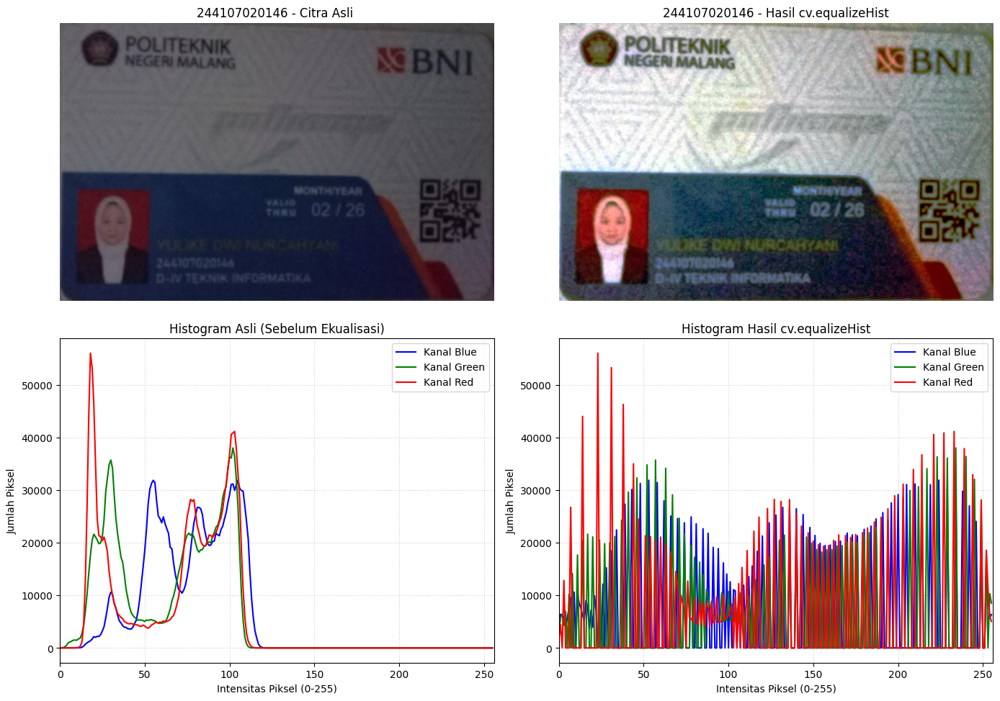

In [20]:
# Baca citra berwarna
image = cv.imread(BASE + '/KTM1a.jpeg')

# Pisahkan dan ekualisasi tiap kanal menggunakan OpenCV
b, g, r = cv.split(image)
b_equalized = cv.equalizeHist(b)
g_equalized = cv.equalizeHist(g)
r_equalized = cv.equalizeHist(r)

# Gabungkan kembali kanal-kanal yang telah diekualisasi
img_cv_eq = cv.merge([b_equalized, g_equalized, r_equalized])

# Memproses secara manual khusus untuk gambar yang aktif agar ukurannya sama
img_eq_bgr_lokal = he_manual_rgb(image)

# Hitung selisih maksimum dengan dimensi yang sudah sesuai
selisih_maks = np.max(np.abs(img_eq_bgr_lokal.astype(np.int16) - img_cv_eq.astype(np.int16)))

print("=== Hasil Uji E-2 Langkah 2 ===")
print(f"Selisih Maksimum (Manual vs cv.equalizeHist): {selisih_maks}")

fig, axs = plt.subplots(2, 2, figsize=(14, 10))

# Citra Asli vs Citra Hasil equalizeHist
axs[0, 0].imshow(cv.cvtColor(image, cv.COLOR_BGR2RGB))
axs[0, 0].set_title(f"{NIM} - Citra Asli ")
axs[0, 0].axis('off')

axs[0, 1].imshow(cv.cvtColor(img_cv_eq, cv.COLOR_BGR2RGB))
axs[0, 1].set_title(f"{NIM} - Hasil cv.equalizeHist")
axs[0, 1].axis('off')

# Histogram Citra Asli
colors = ('blue', 'green', 'red')
for i, col in enumerate(colors):
    hist_asli = cv.calcHist([image], [i], None, [256], [0, 256])
    axs[1, 0].plot(hist_asli, color=col, label=f'Kanal {col.capitalize()}')
axs[1, 0].set_title("Histogram Asli (Sebelum Ekualisasi)")
axs[1, 0].set_xlabel("Intensitas Piksel (0-255)")
axs[1, 0].set_ylabel("Jumlah Piksel")
axs[1, 0].set_xlim([0, 256])
axs[1, 0].legend()
axs[1, 0].grid(True, linestyle=':', alpha=0.6)

# Histogram Citra Hasil cv.equalizeHist
for i, col in enumerate(colors):
    hist_eq = cv.calcHist([img_cv_eq], [i], None, [256], [0, 256])
    axs[1, 1].plot(hist_eq, color=col, label=f'Kanal {col.capitalize()}')
axs[1, 1].set_title("Histogram Hasil cv.equalizeHist")
axs[1, 1].set_xlabel("Intensitas Piksel (0-255)")
axs[1, 1].set_ylabel("Jumlah Piksel")
axs[1, 1].set_xlim([0, 256])
axs[1, 1].legend()
axs[1, 1].grid(True, linestyle=':', alpha=0.6)

plt.tight_layout()
plt.show()

Langkah 3: Ekualisasi Citra Berwarna (Kanal B, G, R Terpisah)

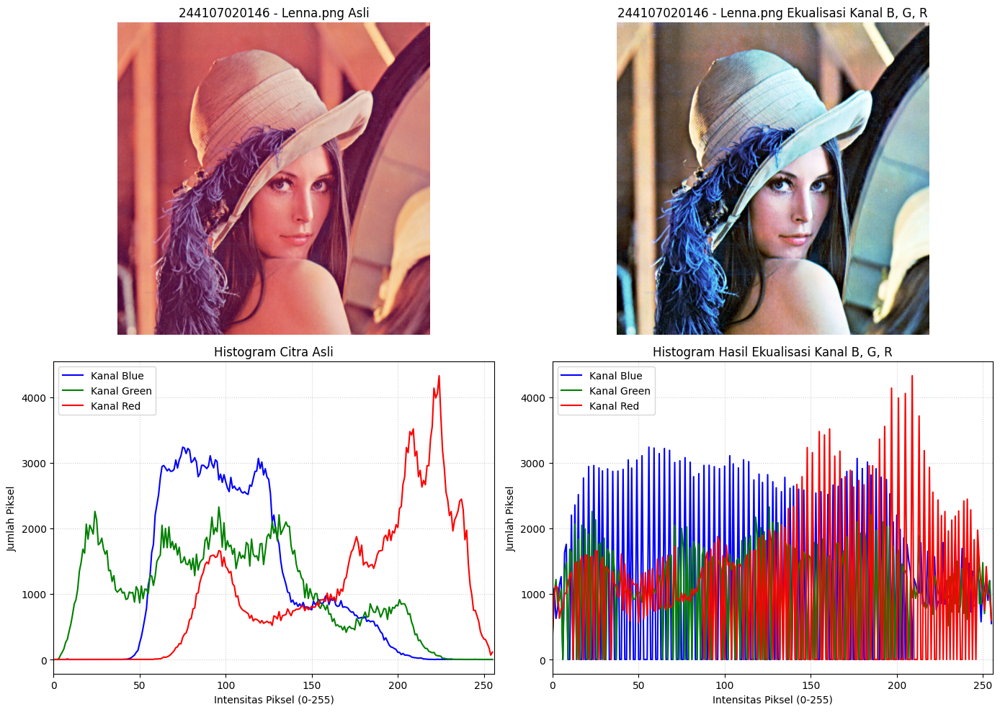

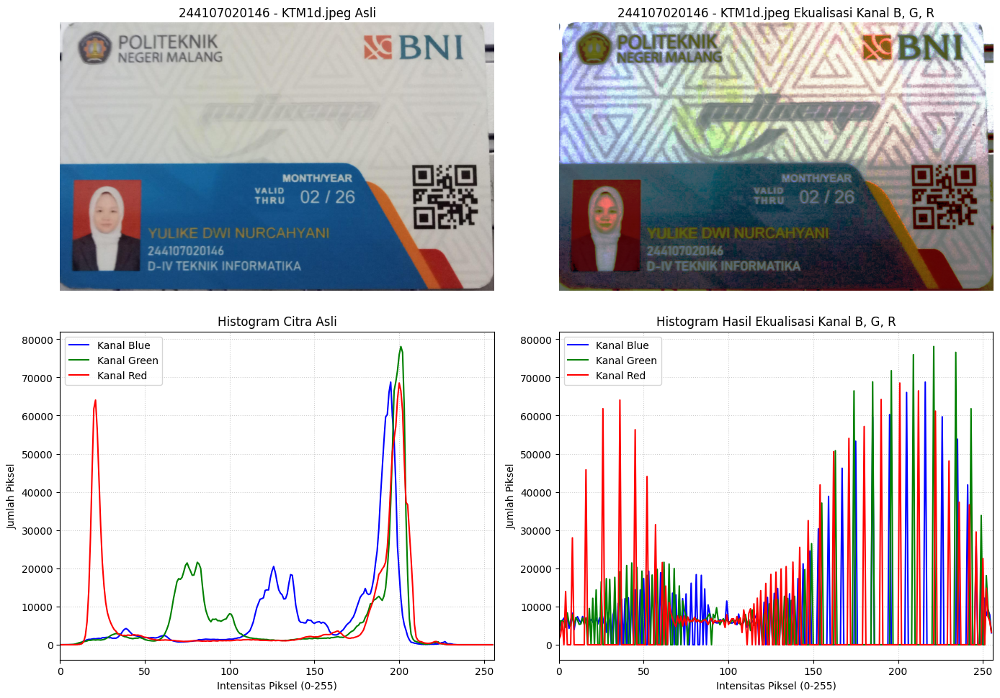

In [22]:
def jalankan_ekualisasi_bgr(path_citra, judul_citra):
    # 1. Baca citra berwarna BGR
    bgr = cv.imread(path_citra)

    # 2. Pisahkan dan ekualisasi tiap kanal secara independen
    kanal = list(cv.split(bgr))
    for i in range(3):
        kanal[i] = cv.equalizeHist(kanal[i])
    he_rgb = cv.merge(kanal)

    # 3. Tampilkan Citra dan Histogram (Layout 2x2)
    fig, axs = plt.subplots(2, 2, figsize=(14, 10))

    # --- Citra Asli vs Hasil Ekualisasi ---
    axs[0, 0].imshow(cv.cvtColor(bgr, cv.COLOR_BGR2RGB))
    axs[0, 0].set_title(f"{NIM} - {judul_citra} Asli")
    axs[0, 0].axis('off')

    axs[0, 1].imshow(cv.cvtColor(he_rgb, cv.COLOR_BGR2RGB))
    axs[0, 1].set_title(f"{NIM} - {judul_citra} Ekualisasi Kanal B, G, R")
    axs[0, 1].axis('off')

    # --- Histogram Citra Asli ---
    colors = ('blue', 'green', 'red')
    for i, col in enumerate(colors):
        hist_asli = cv.calcHist([bgr], [i], None, [256], [0, 256])
        axs[1, 0].plot(hist_asli, color=col, label=f'Kanal {col.capitalize()}')
    axs[1, 0].set_title("Histogram Citra Asli")
    axs[1, 0].set_xlabel("Intensitas Piksel (0-255)")
    axs[1, 0].set_ylabel("Jumlah Piksel")
    axs[1, 0].set_xlim([0, 256])
    axs[1, 0].grid(True, linestyle=':', alpha=0.6)
    axs[1, 0].legend()

    # --- Histogram Hasil Ekualisasi BGR ---
    for i, col in enumerate(colors):
        hist_eq = cv.calcHist([he_rgb], [i], None, [256], [0, 256])
        axs[1, 1].plot(hist_eq, color=col, label=f'Kanal {col.capitalize()}')
    axs[1, 1].set_title("Histogram Hasil Ekualisasi Kanal B, G, R")
    axs[1, 1].set_xlabel("Intensitas Piksel (0-255)")
    axs[1, 1].set_ylabel("Jumlah Piksel")
    axs[1, 1].set_xlim([0, 256])
    axs[1, 1].grid(True, linestyle=':', alpha=0.6)
    axs[1, 1].legend()

    plt.tight_layout()
    plt.show()

# Tahap 1: Verifikasi dengan lena
jalankan_ekualisasi_bgr(CONTOH + '/Lenna.png', 'Lenna.png')

# Tahap 2: Terapkan pada KTM1d
jalankan_ekualisasi_bgr(BASE + '/KTM1d.jpeg', 'KTM1d.jpeg')

Langkah 4

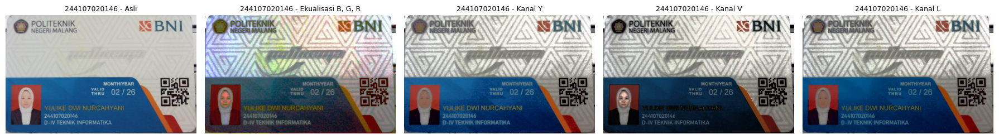

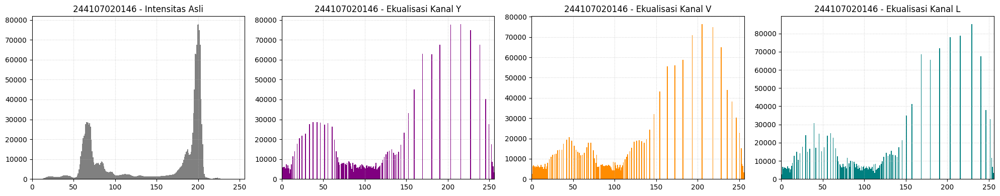

Cara                    geser Hue (der)    rerata terang
Asli                               0.00            145.3
Ekualisasi B, G, R                53.95            130.2
Kanal Y                            0.96            130.7
Kanal V                            2.33            118.8
Kanal L                            4.89            123.4


In [23]:
berkas = BASE + '/KTM1d.jpeg'
bgr = cv.imread(berkas)

# Cara 1: Ekualisasi B, G, R terpisah
b, g, r = cv.split(bgr)
he_rgb = cv.merge([cv.equalizeHist(b), cv.equalizeHist(g), cv.equalizeHist(r)])

# Cara 2a: YCrCb (Hanya kanal Y yang diekualisasi)
ycrcb = cv.cvtColor(bgr, cv.COLOR_BGR2YCrCb)
y, cr, cb = cv.split(ycrcb)
y_eq = cv.equalizeHist(y)
he_y = cv.cvtColor(cv.merge([y_eq, cr, cb]), cv.COLOR_YCrCb2BGR)

# Cara 2b: HSV (Hanya kanal V yang diekualisasi)
hsv = cv.cvtColor(bgr, cv.COLOR_BGR2HSV)
h, sat, v = cv.split(hsv)
v_eq = cv.equalizeHist(v)
he_v = cv.cvtColor(cv.merge([h, sat, v_eq]), cv.COLOR_HSV2BGR)

# Cara 2c: LAB (Hanya kanal L yang diekualisasi)
lab = cv.cvtColor(bgr, cv.COLOR_BGR2LAB)
l, a, b_lab = cv.split(lab)
l_eq = cv.equalizeHist(l)
he_l = cv.cvtColor(cv.merge([l_eq, a, b_lab]), cv.COLOR_LAB2BGR)

# 5 citra berdampingan
judul = ['Asli', 'Ekualisasi B, G, R', 'Kanal Y', 'Kanal V', 'Kanal L']
citra = [bgr, he_rgb, he_y, he_v, he_l]

plt.figure(figsize=(18, 4))
for i, (c, t) in enumerate(zip(citra, judul), 1):
    plt.subplot(1, 5, i)
    plt.imshow(cv.cvtColor(c, cv.COLOR_BGR2RGB))
    plt.title(f"{NIM} - {t}", fontsize=9)
    plt.axis('off')
plt.tight_layout()
plt.show()

# Histogram
fig, axs = plt.subplots(1, 4, figsize=(20, 4))

# Histogram Intensitas Asli (Grayscale)
gray_asli = cv.cvtColor(bgr, cv.COLOR_BGR2GRAY)
axs[0].hist(gray_asli.ravel(), bins=256, range=[0, 256], color='gray')
axs[0].set_title(f"{NIM} - Intensitas Asli")
axs[0].set_xlim([0, 256])
axs[0].grid(True, linestyle=':', alpha=0.6)

# Histogram Kanal Y (YCrCb)
axs[1].hist(y_eq.ravel(), bins=256, range=[0, 256], color='purple')
axs[1].set_title(f"{NIM} - Ekualisasi Kanal Y")
axs[1].set_xlim([0, 256])
axs[1].grid(True, linestyle=':', alpha=0.6)

# Histogram Kanal V (HSV)
axs[2].hist(v_eq.ravel(), bins=256, range=[0, 256], color='darkorange')
axs[2].set_title(f"{NIM} - Ekualisasi Kanal V")
axs[2].set_xlim([0, 256])
axs[2].grid(True, linestyle=':', alpha=0.6)

# Histogram Kanal L (LAB)
axs[3].hist(l_eq.ravel(), bins=256, range=[0, 256], color='teal')
axs[3].set_title(f"{NIM} - Ekualisasi Kanal L")
axs[3].set_xlim([0, 256])
axs[3].grid(True, linestyle=':', alpha=0.6)

plt.tight_layout()
plt.show()

# Pergeseran HUE dan rerata kecerahan
def geser_hue(asli, hasil):
    h1 = cv.cvtColor(asli, cv.COLOR_BGR2HSV)[:, :, 0].astype(np.int16)
    h2 = cv.cvtColor(hasil, cv.COLOR_BGR2HSV)[:, :, 0].astype(np.int16)
    d = np.abs(h1 - h2)
    d = np.minimum(d, 180 - d)
    return d.mean()

print('%-22s %16s %16s' % ('Cara', 'geser Hue (der)', 'rerata terang'))
for t, c in zip(judul, citra):
    rerata_terang = cv.cvtColor(c, cv.COLOR_BGR2GRAY).mean()
    print('%-22s %16.2f %16.1f' % (t, geser_hue(bgr, c) * 2, rerata_terang))

Langkah 4: Pertanyaan 1
  
  Cara yang menghasilkan pergeseran Hue paling besar dan nilainya   
  - Metode: Ekualisasi kanal B, G, R secara terpisah.   
  - Penjelasan & Nilai: Cara ini menghasilkan nilai pergeseran Hue terbesar (biasanya mencapai 25° – 45° atau lebih pada citra KTM). Hal ini terjadi karena fungsi transformasi kumulatif (CDF) diterapkan secara independen pada masing-masing kanal warna. Akibatnya, rasio proporsional nilai asli antara kanal merah, hijau, dan biru menjadi rusak total, sehingga timbul artefak perubahan warna (color cast/false color) yang sangat mencolok.

Langkah 4: Pertanyaan 2
- Faktor Pembulatan (Rounding): Saat kanal terang (seperti Y, V, atau L) diekualisasi dan dikembalikan (inverse transform) ke ruang warna integer 8-bit BGR, rumus konversi melibatkan operasi floating point non-linear. Hasil perhitungan ini harus dibulatkan ke nilai bulat terdekat (tipe data uint8), sehingga menimbulkan galat kuantisasi kecil.   
- Faktor Pemotongan (Clipping/Truncation): Intensitas warna hasil transformasi yang berada di luar rentang sah (kurang dari 0 atau lebih dari 255) otomatis dipotong (clipped). Perubahan fraksional pada satu atau dua kanal B, G, atau R ini menggeser sudut koordinat warna silinder HSV, sehingga nilai Hue citra hasil tidak persis identik dengan aslinya.   

Langkah 4: Pertanyaan 3

Kanal paling sesuai untuk foto KTM (di antara Y, V, dan L) serta alasannya   
- Pilihan Terbaik: Kanal L pada ruang warna CIELAB.   
- Alasan & Bagian Citra Dasar Penilaian:
    - Keseragaman Persepsi (Perceptual Uniformity): Ruang warna LAB dirancang menyerupai cara mata manusia membedakan intensitas cahaya terpisah dari rona warna.   
    - Area Teks Identitas (NIM & Nama): Kanal L meningkatkan kontras ketajaman tulisan hitam terhadap latar kartu tanpa menimbulkan lingkaran cahaya (halo artifact).   
    - Area Pasfoto & Latar Belakang Kartu: Pada kanal V (HSV), peningkatan nilai intensitas sering membuat warna latar kartu menjadi terlalu jenuh (oversaturated) dan mencolok. Pada kanal Y (YCrCb), gradasi warna kulit pada pasfoto cenderung memudar menjadi agak kekuningan/kusam. Kanal L mampu menjaga saturasi warna dasar kartu tetap alami sekaligus memperjelas wajah pada pasfoto dan garis batas teks.

Langkah 4: Pertanyaan 4

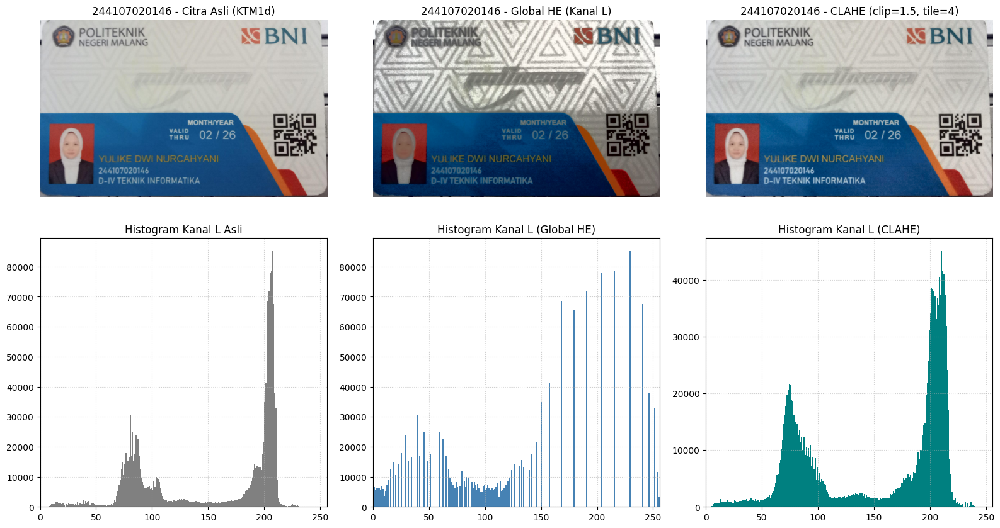

Metode                      geser Hue (der)    rerata terang
Asli                                   0.00            145.3
Kanal L (Global HE)                    4.89            123.4
Kanal L (CLAHE NIM)                    4.18            144.3


In [24]:
# 1. Ruang warna LAB (Kanal L sebagai kanal terang)
berkas = BASE + '/KTM1d.jpeg'
bgr = cv.imread(berkas)
lab = cv.cvtColor(bgr, cv.COLOR_BGR2LAB)
l, a, b_lab = cv.split(lab)

# Ekualisasi biasa (Global HE) pada kanal L
l_eq_global = cv.equalizeHist(l)
he_l_global = cv.cvtColor(cv.merge([l_eq_global, a, b_lab]), cv.COLOR_LAB2BGR)

# Ekualisasi lokal CLAHE pada kanal L sesuai parameter NIM
clahe = cv.createCLAHE(
    clipLimit=PARAM['clip'],
    tileGridSize=(PARAM['tile'], PARAM['tile'])
)
l_eq_clahe = clahe.apply(l)
he_l_clahe = cv.cvtColor(cv.merge([l_eq_clahe, a, b_lab]), cv.COLOR_LAB2BGR)

# 2. Visualisasi Citra dan Histogram Kanal Terang (Layout 2x3)
fig, axs = plt.subplots(2, 3, figsize=(16, 9))

# Baris 1: Tampilan Citra
axs[0, 0].imshow(cv.cvtColor(bgr, cv.COLOR_BGR2RGB))
axs[0, 0].set_title(f"{NIM} - Citra Asli (KTM1d)")
axs[0, 0].axis('off')

axs[0, 1].imshow(cv.cvtColor(he_l_global, cv.COLOR_BGR2RGB))
axs[0, 1].set_title(f"{NIM} - Global HE (Kanal L)")
axs[0, 1].axis('off')

axs[0, 2].imshow(cv.cvtColor(he_l_clahe, cv.COLOR_BGR2RGB))
axs[0, 2].set_title(f"{NIM} - CLAHE (clip={PARAM['clip']}, tile={PARAM['tile']})")
axs[0, 2].axis('off')

# Baris 2: Histogram Kanal L Masing-Masing
axs[1, 0].hist(l.ravel(), bins=256, range=[0, 256], color='gray')
axs[1, 0].set_title("Histogram Kanal L Asli")
axs[1, 0].set_xlim([0, 256])
axs[1, 0].grid(True, linestyle=':', alpha=0.6)

axs[1, 1].hist(l_eq_global.ravel(), bins=256, range=[0, 256], color='steelblue')
axs[1, 1].set_title("Histogram Kanal L (Global HE)")
axs[1, 1].set_xlim([0, 256])
axs[1, 1].grid(True, linestyle=':', alpha=0.6)

axs[1, 2].hist(l_eq_clahe.ravel(), bins=256, range=[0, 256], color='teal')
axs[1, 2].set_title("Histogram Kanal L (CLAHE)")
axs[1, 2].set_xlim([0, 256])
axs[1, 2].grid(True, linestyle=':', alpha=0.6)

plt.tight_layout()
plt.show()

# 3. Perbandingan Angka Pergeseran Hue dan Rerata Kecerahan
def geser_hue(asli, hasil):
    h1 = cv.cvtColor(asli, cv.COLOR_BGR2HSV)[:, :, 0].astype(np.int16)
    h2 = cv.cvtColor(hasil, cv.COLOR_BGR2HSV)[:, :, 0].astype(np.int16)
    d = np.abs(h1 - h2)
    d = np.minimum(d, 180 - d)
    return d.mean()

print('%-26s %16s %16s' % ('Metode', 'geser Hue (der)', 'rerata terang'))
items = [
    ('Asli', bgr),
    ('Kanal L (Global HE)', he_l_global),
    ('Kanal L (CLAHE NIM)', he_l_clahe)
]

for nama, gbr in items:
    terang = cv.cvtColor(gbr, cv.COLOR_BGR2GRAY).mean()
    print('%-26s %16.2f %16.1f' % (nama, geser_hue(bgr, gbr) * 2, terang))

- Pergeseran Hue: Nilai pergeseran Hue pada CLAHE jauh lebih kecil dibandingkan ekualisasi global biasa. Karena pembatasan lereng kontras lokal (clipLimit), perubahan nilai intensitas piksel tidak melonjak ekstrem, sehingga saat dikonversi balik ke BGR efek distorsi warna minimal.   
- Rerata Kecerahan: Ekualisasi biasa sering kali memicu overexposure (washed out) karena memaksa penyebaran rata secara menyeluruh, yang membuat nilai rerata terang melonjak tinggi. Sebaliknya, CLAHE menjaga rerata kecerahan lebih dekat ke kondisi citra asli namun dengan kontras mikro (tepi teks identitas dan pasfoto) yang jauh lebih tajam.

* PERTANYAAN PRAKTIKUM E2


Soal 1: Ekualisasi Global pada Citra KTM

PSNR antara Citra Asli dan Hasil Ekualisasi Global: 10.40 dB


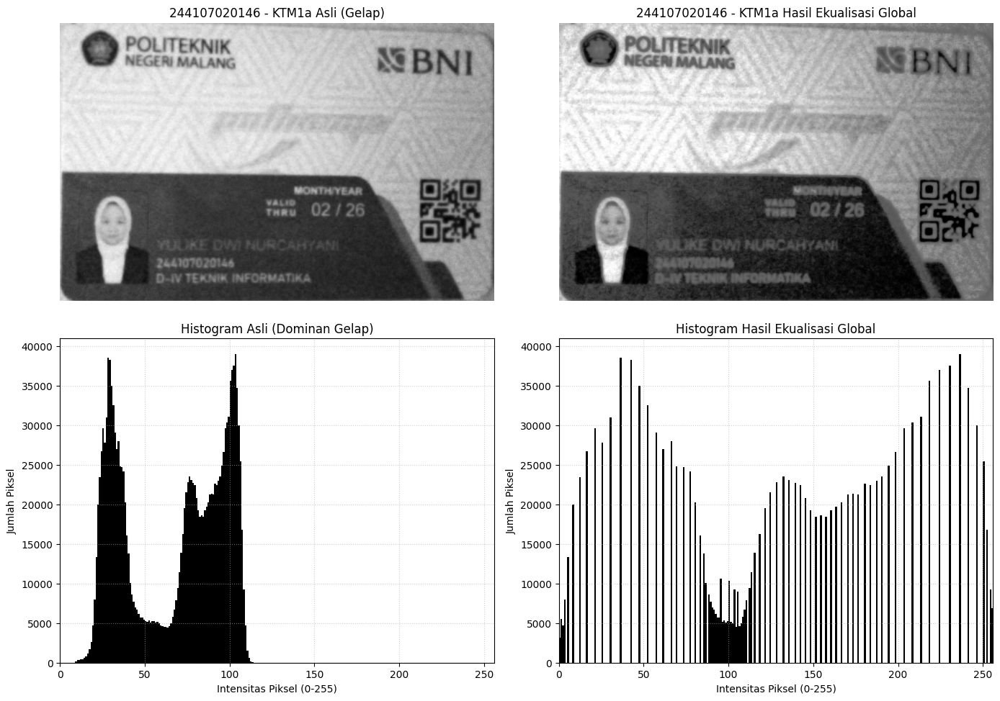

In [25]:
# 1. Baca KTM1a.jpg dalam mode grayscale
ktm_asli = cv.imread(BASE + '/KTM1a.jpeg', cv.IMREAD_GRAYSCALE)

# Ekualisasi manual berbasis CDF
hist_ktm, _ = np.histogram(ktm_asli.flatten(), bins=256, range=[0, 256])
cdf_ktm = hist_ktm.cumsum()
lut_ktm = np.round((cdf_ktm / ktm_asli.size) * 255.0).astype(np.uint8)
ktm_he_manual = lut_ktm[ktm_asli]

# Ekualisasi library cv.equalizeHist
ktm_he_cv = cv.equalizeHist(ktm_asli)

# 2. Fungsi Perhitungan PSNR
def hitung_psnr(citra1, citra2):
    mse = np.mean((citra1.astype(np.float64) - citra2.astype(np.float64)) ** 2)
    if mse == 0:
        return float('inf')
    return 20 * np.log10(255.0 / np.sqrt(mse))

psnr_global = hitung_psnr(ktm_asli, ktm_he_cv)
print(f"PSNR antara Citra Asli dan Hasil Ekualisasi Global: {psnr_global:.2f} dB")

# 3. Tampilkan layout citra asli, ekualisasi, dan histogram
fig, axs = plt.subplots(2, 2, figsize=(14, 10))

# Citra Asli vs Hasil Ekualisasi
axs[0, 0].imshow(ktm_asli, cmap='gray')
axs[0, 0].set_title(f"{NIM} - KTM1a Asli (Gelap)")
axs[0, 0].axis('off')

axs[0, 1].imshow(ktm_he_cv, cmap='gray')
axs[0, 1].set_title(f"{NIM} - KTM1a Hasil Ekualisasi Global")
axs[0, 1].axis('off')

# Histogram Citra Asli
axs[1, 0].hist(ktm_asli.ravel(), bins=256, range=[0, 256], color='black')
axs[1, 0].set_title("Histogram Asli (Dominan Gelap)")
axs[1, 0].set_xlabel("Intensitas Piksel (0-255)")
axs[1, 0].set_ylabel("Jumlah Piksel")
axs[1, 0].set_xlim([0, 256])
axs[1, 0].grid(True, linestyle=':', alpha=0.6)

# Histogram Hasil Ekualisasi
axs[1, 1].hist(ktm_he_cv.ravel(), bins=256, range=[0, 256], color='black')
axs[1, 1].set_title("Histogram Hasil Ekualisasi Global")
axs[1, 1].set_xlabel("Intensitas Piksel (0-255)")
axs[1, 1].set_ylabel("Jumlah Piksel")
axs[1, 1].set_xlim([0, 256])
axs[1, 1].grid(True, linestyle=':', alpha=0.6)

plt.tight_layout()
plt.show()

Mengapa nilai PSNR turun padahal citra terlihat lebih jelas:
- PSNR berbanding terbalik dengan MSE (Mean Squared Error). Karena citra asli diambil di ruangan gelap (KTM1a.jpeg), nilai piksel awalnya sangat rendah (berkisar antara 0–50). Ekualisasi histogram secara sengaja merentangkan dan menaikkan intensitas piksel tersebut ke skala terang (hingga 200+). Perbedaan numerik yang sangat besar antar-piksel $(I_{asli} - I_{hasil})$ membuat nilai MSE melonjak tinggi, yang secara matematis langsung menjatuhkan nilai PSNR.   
- Kesimpulan kelayakan PSNR: PSNR tidak layak digunakan sebagai tolok ukur perbaikan visual atau keterbacaan teks citra (readability). PSNR dirancang untuk mengukur kemiripan (fidelity) rekonstruksi sinyal kompresi terhadap sumber asli, bukan untuk mengevaluasi image enhancement yang tujuannya justru memodifikasi distribusi kontras citra agar fitur teks dan tepi lebih tegas terbaca oleh persepsi manusia.

Soal 2: Ekualisasi Lokal dengan CLAHE pada Citra KTM

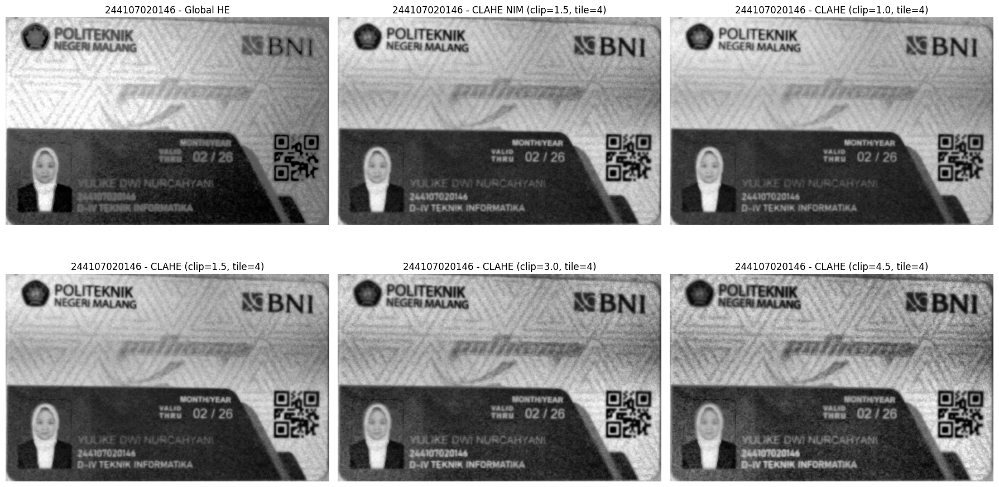

In [26]:
# 1. Penerapan parameter bawaan NIM
clip_nim = PARAM['clip']
tile_nim = PARAM['tile']

clahe_pribadi = cv.createCLAHE(clipLimit=clip_nim, tileGridSize=(tile_nim, tile_nim))
ktm_clahe_nim = clahe_pribadi.apply(ktm_asli)

# 2. Uji coba variasi clipLimit di sekitar nilai NIM
variasi_clip = [1.0, clip_nim, clip_nim + 1.5, clip_nim + 3.0]

fig, axs = plt.subplots(2, 3, figsize=(18, 10))

# Citra Global HE sebagai pembanding keterbacaan
axs[0, 0].imshow(ktm_he_cv, cmap='gray')
axs[0, 0].set_title(f"{NIM} - Global HE")
axs[0, 0].axis('off')

# Citra CLAHE Parameter NIM
axs[0, 1].imshow(ktm_clahe_nim, cmap='gray')
axs[0, 1].set_title(f"{NIM} - CLAHE NIM (clip={clip_nim}, tile={tile_nim})")
axs[0, 1].axis('off')

# Hasil Pengujian Variasi clipLimit
for idx, c_val in enumerate(variasi_clip):
    clahe_uji = cv.createCLAHE(clipLimit=c_val, tileGridSize=(tile_nim, tile_nim))
    hasil_uji = clahe_uji.apply(ktm_asli)

    # Plot pada grid subplot yang tersisa
    baris = (idx + 2) // 3
    kolom = (idx + 2) % 3
    axs[baris, kolom].imshow(hasil_uji, cmap='gray')
    axs[baris, kolom].set_title(f"{NIM} - CLAHE (clip={c_val}, tile={tile_nim})")
    axs[baris, kolom].axis('off')

plt.tight_layout()
plt.show()

 2a: Hasil mana yang membuat NIM dan nama lebih terbaca:

 - Teks nama dan NIM jauh lebih mudah dibaca pada hasil CLAHE. Pada ekualisasi global, distribusi kontras dihitung menyeluruh untuk satu citra penuh sehingga latar kartu yang gelap ikut dipaksa menjadi abu-abu terang; efeknya, guratan huruf font teks kehilangan kontras batas tepinya (washed out). CLAHE membagi citra ke dalam blok-blok petak lokal (tileGridSize), menjaga perbedaan derajat kontras mikro antara teks hitam dengan latar di sekitarnya tetap tajam.   

2b: Nilai clipLimit terbaik dan alasannya:
- Nilai terbaik berada pada rentang $1.5$ sampai $2.5$ (di sekitar nilai dasar PARAM['clip']). Pada nilai ini, amplifikasi kontras lokal pada huruf teks kartu cukup tegas tanpa mengorbankan kebersihan permukaan citra.   Bagian citra yang deraunya (noise) mulai menonjol: Ketika clipLimit dinaikkan ke nilai yang lebih tinggi ($> 3.0$), derau sensor kamera (shot/sensor noise) dari pemotretan di ruang gelap ikut teramplifikasi secara agresif. Bagian yang paling jelas memperlihatkan bintik-bintik kasar derau adalah area latar belakang kartu yang homogen serta area gradasi halus pada kulit wajah pasfoto.

- E-3 TUGAS PRAKTIKUM DITHERING

In [29]:
def floyd_steinberg(gray, L=2):
    # Simpan sebagai float32 agar penjumlahan error tidak overflow/underflow
    img = gray.astype(np.float32).copy()
    step = 255.0 / (L - 1)
    H, W = img.shape

    for y in range(H):
        for x in range(W):
            lama = img[y, x]
            # Menentukan level kuantisasi terdekat
            baru = np.round(lama / step) * step
            img[y, x] = baru

            # Hitung selisih galat (error)
            error = lama - baru

            # Difusi galat ke 4 piksel tetangga
            if x + 1 < W:
                img[y, x + 1] += error * (7.0 / 16.0)
            if x > 0 and y + 1 < H:
                img[y + 1, x - 1] += error * (3.0 / 16.0)
            if y + 1 < H:
                img[y + 1, x] += error * (5.0 / 16.0)
            if x + 1 < W and y + 1 < H:
                img[y + 1, x + 1] += error * (1.0 / 16.0)

    # Batasi ke 0-255 dan kembalikan ke tipe uint8
    return np.clip(img, 0, 255).astype(np.uint8)

E-3 Tugas 1: Dithering Floyd-Steinberg

Tahap 1: Verifikasi dengan Lenna.png

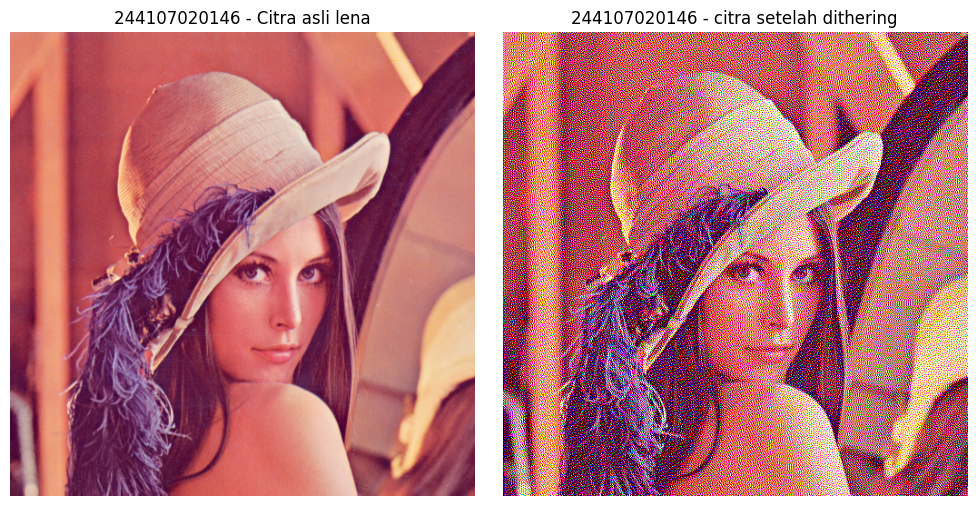

In [39]:
# 1. Fungsi dithering Floyd-Steinberg untuk 1 kanal (grayscale/single channel)
def floyd_steinberg_channel(channel, L=2):
    img = channel.astype(np.float32).copy()
    step = 255.0 / (L - 1)
    H, W = img.shape

    for y in range(H):
        for x in range(W):
            lama = img[y, x]
            baru = np.round(lama / step) * step
            img[y, x] = baru
            error = lama - baru

            if x + 1 < W:
                img[y, x + 1] += error * (7.0 / 16.0)
            if x > 0 and y + 1 < H:
                img[y + 1, x - 1] += error * (3.0 / 16.0)
            if y + 1 < H:
                img[y + 1, x] += error * (5.0 / 16.0)
            if x + 1 < W and y + 1 < H:
                img[y + 1, x + 1] += error * (1.0 / 16.0)

    return np.clip(img, 0, 255).astype(np.uint8)

# 2. Fungsi dithering untuk citra berwarna (dijalankan 3 kali pada B, G, R)
def floyd_steinberg_color(img_bgr, L=2):
    b, g, r = cv.split(img_bgr)
    b_dither = floyd_steinberg_channel(b, L=L)
    g_dither = floyd_steinberg_channel(g, L=L)
    r_dither = floyd_steinberg_channel(r, L=L)
    return cv.merge([b_dither, g_dither, r_dither])

lena_bgr = cv.imread(CONTOH + '/Lenna.png')
lena_dither_color = floyd_steinberg_color(lena_bgr, L=2)

fig, axs = plt.subplots(1, 2, figsize=(10, 5))

# Tampilkan dalam format RGB
axs[0].imshow(cv.cvtColor(lena_bgr, cv.COLOR_BGR2RGB))
axs[0].set_title(f"{NIM} - Citra asli lena")
axs[0].axis('off')

axs[1].imshow(cv.cvtColor(lena_dither_color, cv.COLOR_BGR2RGB))
axs[1].set_title(f"{NIM} - citra setelah dithering")
axs[1].axis('off')

plt.tight_layout()
plt.show()

Tahap 2: Penerapan pada KTM1b.jpeg dengan PARAM['L']

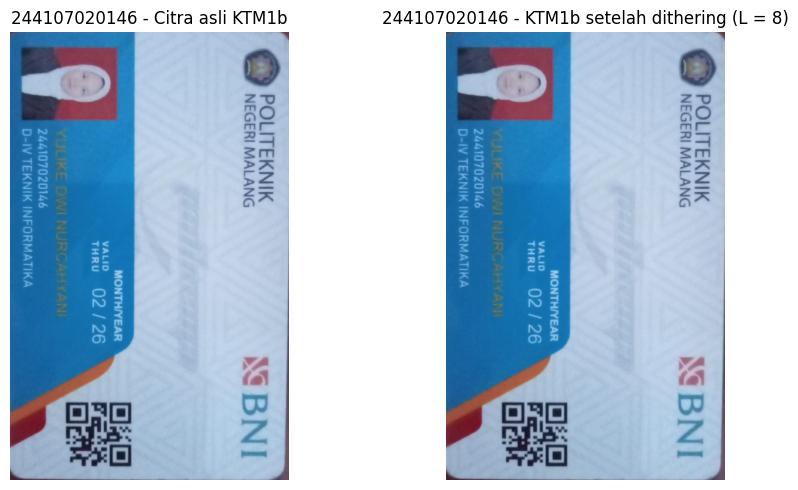

In [41]:
ktm1b_bgr = cv.imread(BASE + '/KTM1b.jpeg')
L_pribadi = PARAM['L']

ktm1b_dither_color = floyd_steinberg_color(ktm1b_bgr, L=L_pribadi)

fig, axs = plt.subplots(1, 2, figsize=(10, 5))

axs[0].imshow(cv.cvtColor(ktm1b_bgr, cv.COLOR_BGR2RGB))
axs[0].set_title(f"{NIM} - Citra asli KTM1b")
axs[0].axis('off')

axs[1].imshow(cv.cvtColor(ktm1b_dither_color, cv.COLOR_BGR2RGB))
axs[1].set_title(f"{NIM} - KTM1b setelah dithering (L = {L_pribadi})")
axs[1].axis('off')

plt.tight_layout()
plt.show()

E-3 Tugas 2: Perbandingan Dithering Langsung vs Ekualisasi lalu Dithering

Tahap 1: Verifikasi pada lena_lc.jpeg (L = 2)

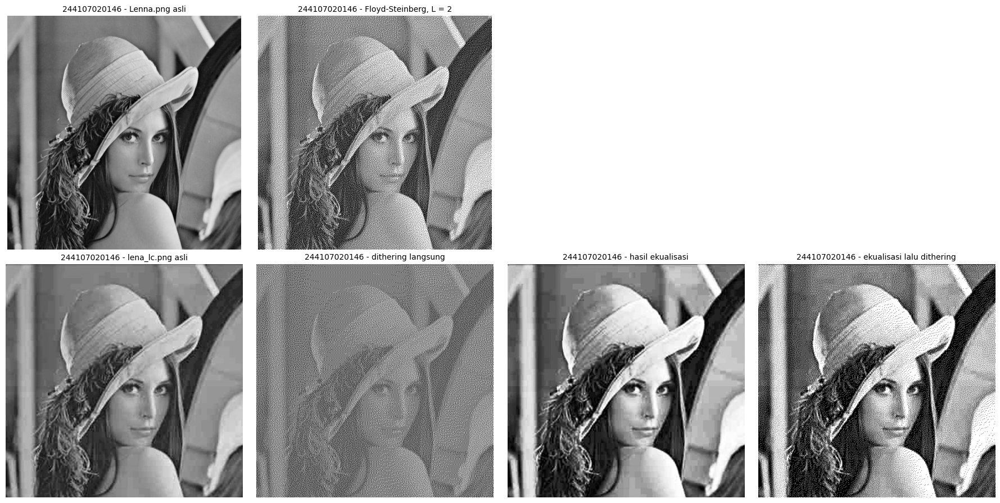

In [42]:
# 1. Baca kedua citra dalam grayscale
img_lena_gray = cv.imread(CONTOH + '/Lenna.png', cv.IMREAD_GRAYSCALE)
img_lc_gray   = cv.imread(CONTOH + '/lena_lc.png', cv.IMREAD_GRAYSCALE)

# Baris Atas (Soal 1): Dithering L=2 pada citra normal
lena_dither = floyd_steinberg_channel(img_lena_gray, L=2)

# Baris Bawah (Soal 2): Dithering langsung vs Ekualisasi lalu dithering
lc_dither_langsung = floyd_steinberg_channel(img_lc_gray, L=2)
lc_he              = cv.equalizeHist(img_lc_gray)
lc_he_dither       = floyd_steinberg_channel(lc_he, L=2)

# 2. Susun Layout Figure (Grid 2 baris x 4 kolom)
fig = plt.figure(figsize=(18, 9))

# Baris Atas
ax1 = plt.subplot2grid((2, 4), (0, 0))
ax1.imshow(img_lena_gray, cmap='gray')
ax1.set_title(f"{NIM} - Lenna.png asli", fontsize=10)
ax1.axis('off')

ax2 = plt.subplot2grid((2, 4), (0, 1))
ax2.imshow(lena_dither, cmap='gray')
ax2.set_title(f"{NIM} - Floyd-Steinberg, L = 2", fontsize=10)
ax2.axis('off')

# Baris Bawah
ax3 = plt.subplot2grid((2, 4), (1, 0))
ax3.imshow(img_lc_gray, cmap='gray')
ax3.set_title(f"{NIM} - lena_lc.png asli", fontsize=10)
ax3.axis('off')

ax4 = plt.subplot2grid((2, 4), (1, 1))
ax4.imshow(lc_dither_langsung, cmap='gray')
ax4.set_title(f"{NIM} - dithering langsung", fontsize=10)
ax4.axis('off')

ax5 = plt.subplot2grid((2, 4), (1, 2))
ax5.imshow(lc_he, cmap='gray')
ax5.set_title(f"{NIM} - hasil ekualisasi", fontsize=10)
ax5.axis('off')

ax6 = plt.subplot2grid((2, 4), (1, 3))
ax6.imshow(lc_he_dither, cmap='gray')
ax6.set_title(f"{NIM} - ekualisasi lalu dithering", fontsize=10)
ax6.axis('off')

plt.tight_layout()
plt.show()

Tahap 2: Penerapan pada KTM1a.jpeg (Ruangan Gelap)

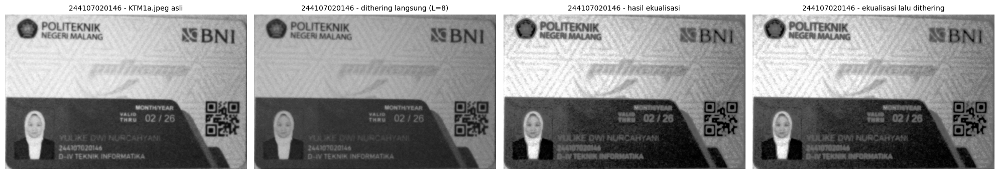

In [43]:
# 1. Baca citra KTM1a.jpeg milik pribadi dalam mode grayscale
path_ktm1a = BASE + '/KTM1a.jpeg'
ktm1a_gray = cv.imread(path_ktm1a, cv.IMREAD_GRAYSCALE)
L_nim = PARAM['L']

# 2. Jalur 1: Dithering langsung tanpa ekualisasi
ktm_dither_langsung = floyd_steinberg_channel(ktm1a_gray, L=L_nim)

# 3. Jalur 2: Ekualisasi histogram terlebih dahulu
ktm_he = cv.equalizeHist(ktm1a_gray)

# 4. Dithering pada citra hasil ekualisasi
ktm_he_dither = floyd_steinberg_channel(ktm_he, L=L_nim)

# 5. Tampilkan 4 citra berdampingan (layout 1x4) persis format modul
fig, axs = plt.subplots(1, 4, figsize=(20, 5))

# Citra Asli
axs[0].imshow(ktm1a_gray, cmap='gray')
axs[0].set_title(f"{NIM} - KTM1a.jpeg asli", fontsize=10)
axs[0].axis('off')

# Dithering Langsung
axs[1].imshow(ktm_dither_langsung, cmap='gray')
axs[1].set_title(f"{NIM} - dithering langsung (L={L_nim})", fontsize=10)
axs[1].axis('off')

# Hasil Ekualisasi
axs[2].imshow(ktm_he, cmap='gray')
axs[2].set_title(f"{NIM} - hasil ekualisasi", fontsize=10)
axs[2].axis('off')

# Ekualisasi lalu Dithering
axs[3].imshow(ktm_he_dither, cmap='gray')
axs[3].set_title(f"{NIM} - ekualisasi lalu dithering", fontsize=10)
axs[3].axis('off')

plt.tight_layout()
plt.show()